## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

In [2]:
def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    gdf1 = pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})

    return pd.concat([gdf1, gdf2, gdf3])

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

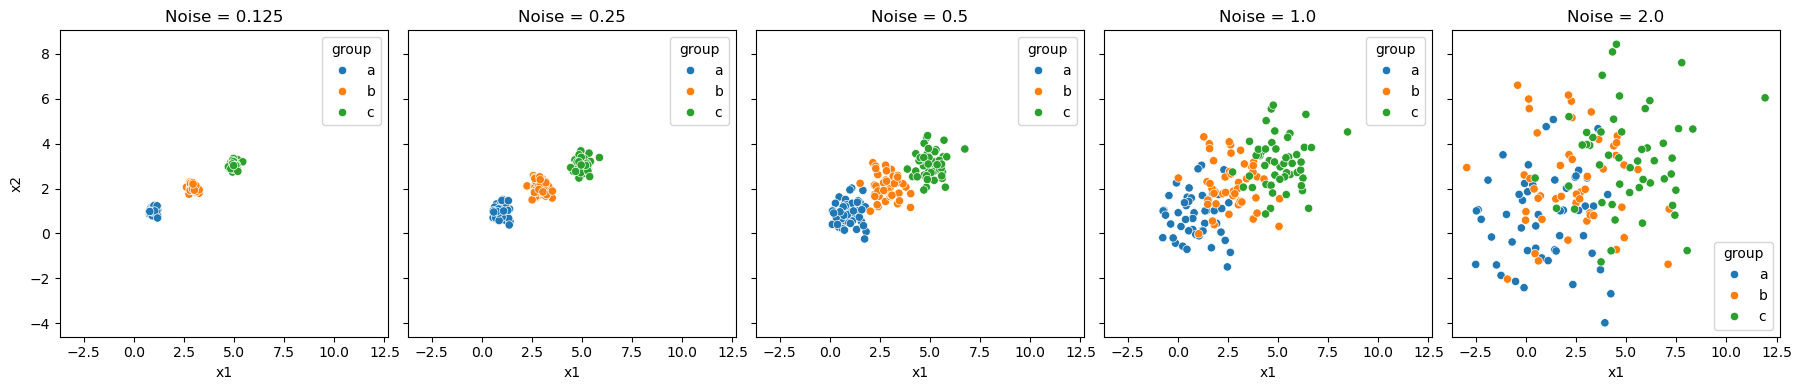

In [3]:
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise = [0.125, 0.25, 0.5, 1.0, 2.0]

fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharex=True, sharey=True)

for i in range(5):
    sns.scatterplot(data=datasets[i], x='x1', y='x2',
                    hue='group', ax=axes[i])
    axes[i].set_title('Noise = ' + str(noise[i]))

plt.tight_layout()
plt.show()

As noise increases, the points spread out more and the clusters become less distinct. At 0.125 and 0.25, the three groups are clearly separated. At 0.5, some overlap starts to appear. At 1.0 and 2.0, the groups overlap much more, making them harder to distinguish.

In [ ]:
plt.figure(figsize=(8, 5))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    sse = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=20)
        model.fit(X)
        sse.append(model.inertia_)

    plt.plot(range(1, 11), sse, marker='o', label=str(noise[i]))

plt.xlabel('k')
plt.ylabel('Within-cluster sum of squares')
plt.xticks(range(1, 11))
plt.legend(title='Noise')
plt.show()

At lower noise levels, the scree plots flatten out after k = 3, so three clusters is a reasonable choice. As noise increases, the curves become smoother and the elbow is less clear. The noisier datasets also have higher within-cluster sums of squares. This makes it harder to confidently choose one value of k.

1.4: The elbow is where adding more clusters starts giving smaller improvements. In the low-noise datasets, using fewer than three clusters combines separate groups, which creates large distances from the cluster centers. At three clusters, each group can have its own center, so additional clusters do not help much. With more noise, the groups overlap and extra clusters can still reduce the variation, making the elbow harder to see.

In [ ]:
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020]
df = df.dropna()
df = df.drop(columns=['index'])

print(len(df))
print(df.dtypes)
print(df['Country'].duplicated().sum())

df.head()

After filtering to 2020 and dropping missing values, there are 148 countries. The four spending variables are already numeric, and there are no duplicate countries. I removed the index column because it is just a row identifier. Country and Year should not be used for clustering. The percentage variables are stored as decimals, so 0.04 means 4%. The numeric variables also need normalization before clustering because they have different scales.

In [ ]:
cols = ['Spending (2020 USD)', 'Spending per Capita']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker='o')
plt.xlabel('k')
plt.ylabel('Within-cluster sum of squares')
plt.xticks(range(1, 11))
plt.show()

I chose k = 4 because the curve becomes much flatter after four clusters. Adding more clusters still reduces the sum of squares, but the improvements are smaller.

In [ ]:
model = KMeans(n_clusters=4, random_state=100, n_init=20)

df['cluster_amount'] = model.fit_predict(X)

sns.scatterplot(data=df, x='Spending (2020 USD)',
                y='Spending per Capita',
                hue='cluster_amount', palette='tab10')

plt.show()

display(df.groupby('cluster_amount')[cols].describe())

display(df.groupby('cluster_amount').size())

display(df[df['Country'] == 'United States of America'])

The clusters contain 111, 30, 1, and 6 countries. Cluster 0 contains most countries and has relatively low spending per person. Cluster 1 has higher spending per person and includes countries such as Canada, Japan, and several European countries. Cluster 2 contains only the United States, which stands out because of its very high total spending and high spending per person. Cluster 3 contains Israel, Kuwait, Norway, Oman, Saudi Arabia, and Singapore, which have especially high spending per person.

China is in cluster 0 despite its high total spending because its spending per person is much lower. This shows that the clusters depend on both variables.

In [ ]:
cols = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker='o')
plt.xlabel('k')
plt.ylabel('Within-cluster sum of squares')
plt.xticks(range(1, 11))
plt.show()

The biggest bend is around k = 2, but I chose k = 3 to separate countries into lower, middle, and higher spending-share groups. The elbow is less clear here, so two clusters would also be a reasonable choice.

In [ ]:
model = KMeans(n_clusters=3, random_state=100, n_init=20)

df['cluster_share'] = model.fit_predict(X)

sns.scatterplot(data=df, x='Percent of Government Spending',
                y='Percent of GDP',
                hue='cluster_share', palette='tab10')

plt.show()

display(df.groupby('cluster_share')[cols].describe())

display(df.groupby('cluster_share').size())

display(df[df['Country'] == 'United States of America'])

Cluster 1 contains 99 countries with relatively low spending shares. Cluster 0 contains 39 countries with intermediate shares, and cluster 2 contains 10 countries with high shares. The high-share group includes countries such as Algeria, Israel, Oman, Pakistan, and Saudi Arabia.

The United States is in the intermediate group instead of being alone. Its military spending is about 3.72% of GDP and 8.20% of government spending. Compared with part 2, these clusters measure how much of a country's resources go toward the military rather than how much money it spends. Norway, for example, has high spending per person but belongs to the low-share group.

In [ ]:
cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

sse = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=20)
    model.fit(X)
    sse.append(model.inertia_)

plt.plot(range(1, 11), sse, marker='o')
plt.xlabel('k')
plt.ylabel('Within-cluster sum of squares')
plt.xticks(range(1, 11))
plt.show()

I chose k = 3 because the curve becomes more gradual after three clusters. There is not a perfectly clear elbow, so four clusters could also be reasonable.

In [ ]:
model = KMeans(n_clusters=3, random_state=100, n_init=20)

df['cluster_all'] = model.fit_predict(X)

sns.scatterplot(data=df, x='Spending (2020 USD)',
                y='Spending per Capita',
                hue='cluster_all', palette='tab10')

plt.show()

display(df.groupby('cluster_all')[cols].describe())

display(df.groupby('cluster_all')[cols].mean())

display(df.groupby('cluster_all').size())

display(df[df['Country'] == 'United States of America'])

Cluster 0 contains 111 countries with relatively low spending shares. Cluster 1 contains Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United States, which have high spending per person. Cluster 2 contains 31 countries with relatively high spending shares.

The United States is no longer alone like it was in part 2. Norway also separates from the high-per-person group and joins cluster 0. Using all four variables combines information about spending amounts and spending shares, so the memberships change. The scatterplot only displays two variables, but the clustering uses all four.

2.5: The algorithm found useful patterns by separating countries based on spending amounts, spending per person, and spending shares. It showed that spending a lot of money does not always mean spending a large share of national resources. The United States stood out in total spending, while other countries stood out more in spending shares. However, the results depend on the variables and k chosen, and extreme values still influence clustering after normalization.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]